# RateBeer multi-aspect reviews: predicting overall beer ratings

Assignment 2 requires a predictive task grounded in exploratory analysis. This notebook loads `ratebeer.json.gz`, examines `review/overall` as the prediction target, and evaluates three candidate ways to predict it: pre-review user and beer context, same-review aspect sub-ratings, and review text. The final section selects the task supported by the data.

**Source.** [Multi-aspect Reviews](https://cseweb.ucsd.edu/~jmcauley/datasets.html#multi_aspect) (Julian McAuley, UCSD; SNAP RateBeer mirror). The published SNAP card reports 2,924,127 reviews, 40,213 users, 110,419 beers, 4,798 users with more than 50 reviews, a median length of 54 words per review, and a timespan of April 2000 through November 2011. The published example record is beer `63836` (*John Harvards Simcoe IPA*), brewer `8481`, ABV `5.4`, style `India Pale Ale (IPA)`, reviewer `hopdog`, and `review/overall = 13/20`.

**Citations.**
- Julian McAuley, Jure Leskovec, and Dan Jurafsky, "Learning attitudes and attributes from multi-aspect reviews," ICDM 2012.
- Julian McAuley and Jure Leskovec, "From amateurs to connoisseurs: modeling the evolution of user expertise through online reviews," WWW 2013.

**How the file is stored.** `ratebeer.json.gz` (~399 MB) is a single gzip layer containing one Python dictionary literal per line with single-quoted keys and values, which is why `pandas.read_json` raises `ValueError`. Style and beer names contain HTML entities (such as `&#40;IPA&#41;`), missing ABV values appear as `'-'`, and one trailing empty `{}` line sits at the end of the file. The loader below parses each line with `ast.literal_eval`, unescapes HTML entities, parses rating numerators, converts Unix timestamps, and collects word counts and streaming token counts before discarding the raw review strings to keep memory compact.

In [3]:
import ast
from collections import Counter
import gzip
import html
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path("ratebeer.json.gz")
ASPECT_SCALES = {
    "appearance": 5.0,
    "aroma": 10.0,
    "palate": 5.0,
    "taste": 10.0,
    "overall": 20.0,
}
ASPECT_FIELDS = {
    "appearance": "review/appearance",
    "aroma": "review/aroma",
    "palate": "review/palate",
    "taste": "review/taste",
    "overall": "review/overall",
}
COLORS = {
    "primary": "#1b4f72",
    "teal": "#148f77",
    "amber": "#b9770e",
    "purple": "#6c3483",
    "crimson": "#922b21",
    "slate": "#566573",
}

# Tail cutoffs for streaming word log-odds (confirmed against the overall histogram below).
LOW_OVERALL_MAX = 10.0
HIGH_OVERALL_MIN = 17.0
TOKEN_RE = re.compile(r"[a-z]{3,}")
STOPWORDS = {
    "the", "and", "for", "with", "this", "that", "from", "are", "was", "were",
    "have", "has", "had", "but", "you", "your", "its", "all", "one", "out",
    "very", "some", "more", "just", "into", "about", "than", "then", "them",
    "they", "there", "their", "what", "when", "which", "will", "would", "could",
    "should", "can", "also", "been", "being", "over", "after", "here", "other",
    "still", "most", "even", "any", "too", "only", "who", "how", "why", "where",
    "while", "through", "before", "under", "between", "both", "each", "few",
    "same", "such", "own", "does", "did", "doing", "don", "didn", "doesn",
    "isn", "wasn", "aren", "won", "ve", "ll", "re", "beer", "brew", "bottle",
    "tap", "pours", "poured", "pour", "glass", "oz", "ml", "cl", "sample",
}

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
})


def _parse_ratio(value: str | None, expected_denom: float) -> tuple[float, bool]:
    if not value or "/" not in value:
        return np.nan, True
    num_s, denom_s = value.split("/", 1)
    return float(num_s), float(denom_s) != expected_denom


def load_ratebeer(path: Path):
    """Stream-parse ratebeer.json.gz into a compact DataFrame plus text token counters."""
    beer_ids, brewer_ids, styles, users = [], [], [], []
    abvs, times, word_counts = [], [], []
    scores = {k: [] for k in ASPECT_SCALES}
    beer_names: dict[str, str] = {}

    low_tokens: Counter[str] = Counter()
    high_tokens: Counter[str] = Counter()
    n_low_docs = 0
    n_high_docs = 0
    skipped_empty = 0
    malformed_lines = 0
    denom_mismatches = 0

    with gzip.open(path, "rt", encoding="utf-8", errors="replace") as fh:
        for raw_line in fh:
            line = raw_line.strip()
            if not line:
                skipped_empty += 1
                continue
            try:
                row = ast.literal_eval(line)
            except (SyntaxError, ValueError):
                malformed_lines += 1
                continue
            if not row:
                skipped_empty += 1
                continue

            bid = str(row["beer/beerId"])
            if bid not in beer_names:
                beer_names[bid] = html.unescape(row.get("beer/name", ""))
            beer_ids.append(bid)
            brewer_ids.append(str(row["beer/brewerId"]))
            styles.append(html.unescape(row.get("beer/style", "")))
            users.append(str(row["review/profileName"]))

            raw_abv = row.get("beer/ABV")
            if raw_abv is None or raw_abv == "-":
                abvs.append(np.nan)
            else:
                try:
                    abvs.append(float(raw_abv))
                except ValueError:
                    abvs.append(np.nan)

            for col, field in ASPECT_FIELDS.items():
                val, bad_denom = _parse_ratio(row.get(field), ASPECT_SCALES[col])
                scores[col].append(val)
                if bad_denom:
                    denom_mismatches += 1

            times.append(int(row["review/time"]))

            text = row.get("review/text") or ""
            wc = len(text.split()) if text else 0
            word_counts.append(wc)

            ov = scores["overall"][-1]
            if wc > 0:
                if ov <= LOW_OVERALL_MAX:
                    n_low_docs += 1
                    low_tokens.update(
                        tok for tok in TOKEN_RE.findall(text.lower()) if tok not in STOPWORDS
                    )
                elif ov >= HIGH_OVERALL_MIN:
                    n_high_docs += 1
                    high_tokens.update(
                        tok for tok in TOKEN_RE.findall(text.lower()) if tok not in STOPWORDS
                    )

    df = pd.DataFrame({
        "user": pd.Categorical(users),
        "beer_id": pd.Categorical(beer_ids),
        "brewer_id": pd.Categorical(brewer_ids),
        "style": pd.Categorical(styles),
        "abv": np.array(abvs, dtype=np.float32),
        "appearance": np.array(scores["appearance"], dtype=np.float32),
        "aroma": np.array(scores["aroma"], dtype=np.float32),
        "palate": np.array(scores["palate"], dtype=np.float32),
        "taste": np.array(scores["taste"], dtype=np.float32),
        "overall": np.array(scores["overall"], dtype=np.float32),
        "review_time": pd.to_datetime(np.array(times, dtype=np.int64), unit="s", utc=True),
        "word_count": np.array(word_counts, dtype=np.int32),
    })
    df["has_text"] = df["word_count"] > 0

    meta = {
        "beer_names": beer_names,
        "low_tokens": low_tokens,
        "high_tokens": high_tokens,
        "n_low_docs": n_low_docs,
        "n_high_docs": n_high_docs,
        "skipped_empty": skipped_empty,
        "malformed_lines": malformed_lines,
        "denom_mismatches": denom_mismatches,
    }
    return df, meta


reviews, meta = load_ratebeer(DATA_PATH)

# Verify against the published dataset-card example (hopdog / beer 63836).
example = reviews.loc[
    (reviews["beer_id"] == "63836") & (reviews["user"] == "hopdog")
].iloc[0]
assert meta["beer_names"]["63836"] == "John Harvards Simcoe IPA"
assert example["brewer_id"] == "8481"
assert example["style"] == "India Pale Ale (IPA)"
assert np.isclose(example["abv"], 5.4)
assert (
    example["appearance"],
    example["aroma"],
    example["palate"],
    example["taste"],
    example["overall"],
) == (4.0, 6.0, 3.0, 6.0, 13.0)

user_counts = reviews.groupby("user", observed=True).size()
card_check = pd.DataFrame([
    {"metric": "reviews", "loaded_file": f"{len(reviews):,}", "snap_card": "2,924,127"},
    {"metric": "unique users", "loaded_file": f"{reviews['user'].nunique():,}", "snap_card": "40,213"},
    {"metric": "unique beers", "loaded_file": f"{reviews['beer_id'].nunique():,}", "snap_card": "110,419"},
    {"metric": "unique brewers", "loaded_file": f"{reviews['brewer_id'].nunique():,}", "snap_card": "—"},
    {"metric": "unique styles", "loaded_file": f"{reviews['style'].nunique():,}", "snap_card": "—"},
    {"metric": "users with > 50 reviews", "loaded_file": f"{(user_counts > 50).sum():,}", "snap_card": "4,798"},
    {"metric": "median words per review", "loaded_file": f"{reviews['word_count'].median():.0f}", "snap_card": "54"},
    {
        "metric": "timespan (UTC)",
        "loaded_file": f"{reviews['review_time'].min().strftime('%Y-%m-%d')} to {reviews['review_time'].max().strftime('%Y-%m-%d')}",
        "snap_card": "Apr 2000 – Nov 2011",
    },
])

print(
    f"Loaded {len(reviews):,} reviews "
    f"(dropped {meta['skipped_empty']} empty record, "
    f"{meta['malformed_lines']} malformed lines, "
    f"{meta['denom_mismatches']} denominator mismatches)."
)
print(f"DataFrame memory: {reviews.memory_usage(deep=True).sum() / 1e6:.1f} MB (raw review text dropped after streaming pass).")
display(card_check)
reviews.head(6)

Loaded 2,924,163 reviews (dropped 1 empty record, 0 malformed lines, 0 denominator mismatches).
DataFrame memory: 147.9 MB (raw review text dropped after streaming pass).


,metric,loaded_file,snap_card
0,reviews,"2,924,163","2,924,127"
1,unique users,"29,265","40,213"
2,unique beers,"110,369","110,419"
3,unique brewers,"7,547",—
4,unique styles,89,—
5,users with > 50 reviews,"4,760","4,798"
6,median words per review,43,54
7,timespan (UTC),2000-04-12 to 2012-01-13,Apr 2000 – Nov 2011


,user,beer_id,brewer_id,style,abv,appearance,aroma,palate,taste,overall,review_time,word_count,has_text
0,hopdog,63836,8481,India Pale Ale (IPA),5.4,4.0,6.0,3.0,6.0,13.0,2006-09-07 00:00:00+00:00,73,True
1,TomDecapolis,63836,8481,India Pale Ale (IPA),5.4,4.0,6.0,4.0,7.0,13.0,2006-09-03 00:00:00+00:00,69,True
2,PhillyBeer2112,71716,8481,Bohemian Pilsener,5.0,4.0,5.0,3.0,6.0,14.0,2000-05-19 00:00:00+00:00,45,True
3,TomDecapolis,64125,8481,Klsch,5.4,2.0,4.0,2.0,4.0,8.0,2006-09-07 00:00:00+00:00,49,True
4,hopdog,64125,8481,Klsch,5.4,2.0,4.0,2.0,4.0,8.0,2006-09-07 00:00:00+00:00,74,True
5,egajdzis,31544,8481,Sweet Stout,NaN,5.0,8.0,4.0,7.0,16.0,2004-02-26 00:00:00+00:00,61,True


## 1. What we would predict: `review/overall` and rating scales

Every review carries an integer `review/overall` score on a 1–20 scale alongside four sensory sub-ratings on different denominators: `appearance` (1–5), `aroma` (1–10), `palate` (1–5), and `taste` (1–10). Dividing each score by its scale maximum places all five dimensions on a common `[0, 1]` scale for comparison. The table and plots below verify range integrity, missingness, and the shape of the target distribution.

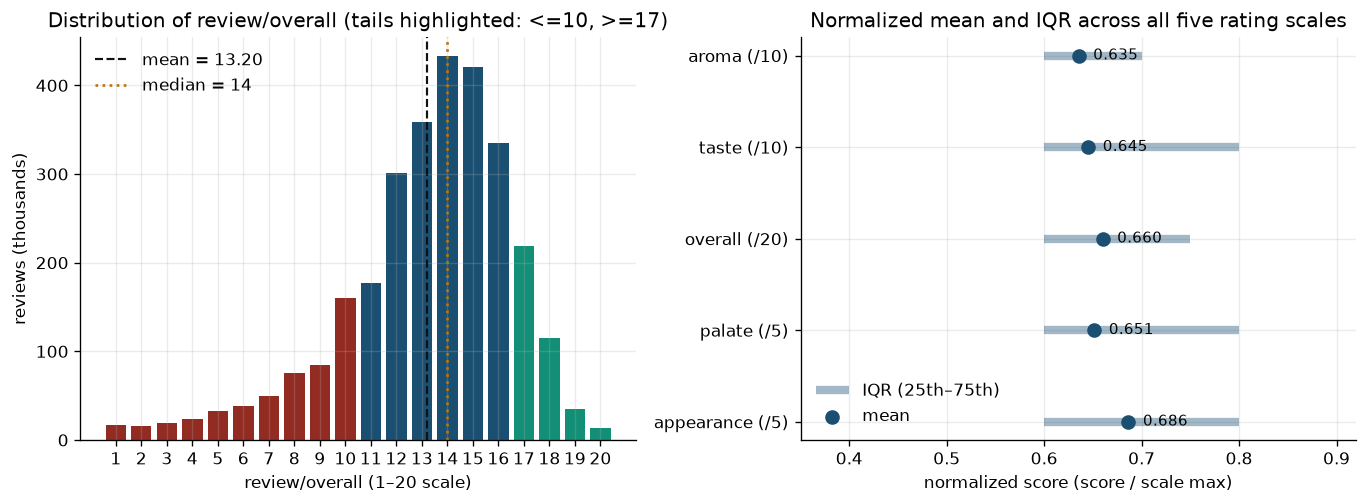

review/overall: mean 13.20, std 3.35, median 14, IQR [12, 15]
Concentration: 63.2% of ratings fall in 12–16; 17.7% are <=10; 13.1% are >=17.
ABV missing in 138,637 reviews (4.74%); zero missing or out-of-range scores across all five rating fields.


,field,scale,missing,missing_pct,out_of_range,min,q1,median,mean,q3,max,std,mean_norm
0,overall,1–20,0,0.000000,0,1.00,12.0,14.0,13.199696,15.0,20.000000,3.352579,0.659985
1,taste,1–10,0,0.000000,0,1.00,6.0,7.0,6.451929,8.0,10.000000,1.622888,0.645193
2,aroma,1–10,0,0.000000,0,1.00,6.0,7.0,6.353608,7.0,10.000000,1.639165,0.635361
3,palate,1–5,0,0.000000,0,1.00,3.0,3.0,3.257236,4.0,5.000000,0.829731,0.651447
4,appearance,1–5,0,0.000000,0,1.00,3.0,3.0,3.432027,4.0,5.000000,0.812557,0.686405
5,abv,% ABV (>0),138637,0.047411,0,0.01,5.0,6.0,6.640794,8.0,57.700001,2.313753,NaN


In [4]:
for col, max_val in ASPECT_SCALES.items():
    reviews[f"{col}_norm"] = (reviews[col] / max_val).astype(np.float32)

quality_rows = []
for col, max_val in [("overall", 20.0), ("taste", 10.0), ("aroma", 10.0), ("palate", 5.0), ("appearance", 5.0)]:
    s = reviews[col].astype(np.float64)
    n_miss = int(s.isna().sum())
    out_of_range = int(((s < 1.0) | (s > max_val)).sum())
    q1, med, q3 = np.nanpercentile(s, [25, 50, 75])
    quality_rows.append({
        "field": col,
        "scale": f"1–{int(max_val)}",
        "missing": n_miss,
        "missing_pct": n_miss / len(reviews),
        "out_of_range": out_of_range,
        "min": float(s.min()),
        "q1": float(q1),
        "median": float(med),
        "mean": float(s.mean()),
        "q3": float(q3),
        "max": float(s.max()),
        "std": float(s.std()),
        "mean_norm": float(s.mean() / max_val),
    })

abv_s = reviews["abv"].astype(np.float64)
abv_miss = int(abv_s.isna().sum())
abv_q1, abv_med, abv_q3 = np.nanpercentile(abv_s, [25, 50, 75])
quality_rows.append({
    "field": "abv",
    "scale": "% ABV (>0)",
    "missing": abv_miss,
    "missing_pct": abv_miss / len(reviews),
    "out_of_range": int((abv_s <= 0).sum()),
    "min": float(abv_s.min()),
    "q1": float(abv_q1),
    "median": float(abv_med),
    "mean": float(abv_s.mean()),
    "q3": float(abv_q3),
    "max": float(abv_s.max()),
    "std": float(abv_s.std()),
    "mean_norm": np.nan,
})
quality_table = pd.DataFrame(quality_rows)

overall_counts = reviews["overall"].value_counts().reindex(range(1, 21), fill_value=0)
overall_mean = float(reviews["overall"].astype(np.float64).mean())
overall_std = float(reviews["overall"].astype(np.float64).std())
overall_med = float(reviews["overall"].median())

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

bar_colors = [
    COLORS["crimson"] if k <= LOW_OVERALL_MAX else (COLORS["teal"] if k >= HIGH_OVERALL_MIN else COLORS["primary"])
    for k in overall_counts.index
]
axes[0].bar(overall_counts.index, overall_counts.values / 1e3, color=bar_colors, width=0.8)
axes[0].axvline(overall_mean, color="#111111", linestyle="--", linewidth=1.3, label=f"mean = {overall_mean:.2f}")
axes[0].axvline(overall_med, color=COLORS["amber"], linestyle=":", linewidth=1.6, label=f"median = {overall_med:.0f}")
axes[0].set_xticks(range(1, 21))
axes[0].set_xlabel("review/overall (1–20 scale)")
axes[0].set_ylabel("reviews (thousands)")
axes[0].set_title("Distribution of review/overall (tails highlighted: <=10, >=17)")
axes[0].legend(frameon=False)

aspect_order = ["appearance", "palate", "overall", "taste", "aroma"]
norm_means = [float(reviews[f"{c}_norm"].astype(np.float64).mean()) for c in aspect_order]
norm_q1 = [float(np.percentile(reviews[f"{c}_norm"], 25)) for c in aspect_order]
norm_q3 = [float(np.percentile(reviews[f"{c}_norm"], 75)) for c in aspect_order]
y_pos = np.arange(len(aspect_order))
axes[1].hlines(y_pos, norm_q1, norm_q3, color=COLORS["primary"], linewidth=5, alpha=0.4, label="IQR (25th–75th)")
axes[1].scatter(norm_means, y_pos, color=COLORS["primary"], s=60, zorder=3, label="mean")
for y_i, m_val in zip(y_pos, norm_means):
    axes[1].text(m_val + 0.015, y_i, f"{m_val:.3f}", va="center", fontsize=9)
axes[1].set_yticks(y_pos, [f"{c} (/{int(ASPECT_SCALES[c])})" for c in aspect_order])
axes[1].set_xlim(0.35, 0.92)
axes[1].set_xlabel("normalized score (score / scale max)")
axes[1].set_title("Normalized mean and IQR across all five rating scales")
axes[1].legend(loc="lower left", frameon=False)

fig.tight_layout()
plt.show()

share_low = float((reviews["overall"] <= LOW_OVERALL_MAX).mean())
share_mid = float(((reviews["overall"] >= 12) & (reviews["overall"] <= 16)).mean())
share_high = float((reviews["overall"] >= HIGH_OVERALL_MIN).mean())
print(f"review/overall: mean {overall_mean:.2f}, std {overall_std:.2f}, median {overall_med:.0f}, IQR [{quality_table.loc[0, 'q1']:.0f}, {quality_table.loc[0, 'q3']:.0f}]")
print(f"Concentration: {share_mid:.1%} of ratings fall in 12–16; {share_low:.1%} are <=10; {share_high:.1%} are >=17.")
print(f"ABV missing in {abv_miss:,} reviews ({abv_miss / len(reviews):.2%}); zero missing or out-of-range scores across all five rating fields.")
quality_table

## 2. User–beer rating prediction (features known before the review)

### 2a. User and beer activity, sparsity, and duplicate pairs

Collaborative filtering and bias models require repeated observations per user and per beer. The distributions below measure the long tail of activity, check how many users and beers pass standard history thresholds (including SNAP's 50-review cutoff), and count repeated `(user, beer)` pairs that affect train/test splitting.

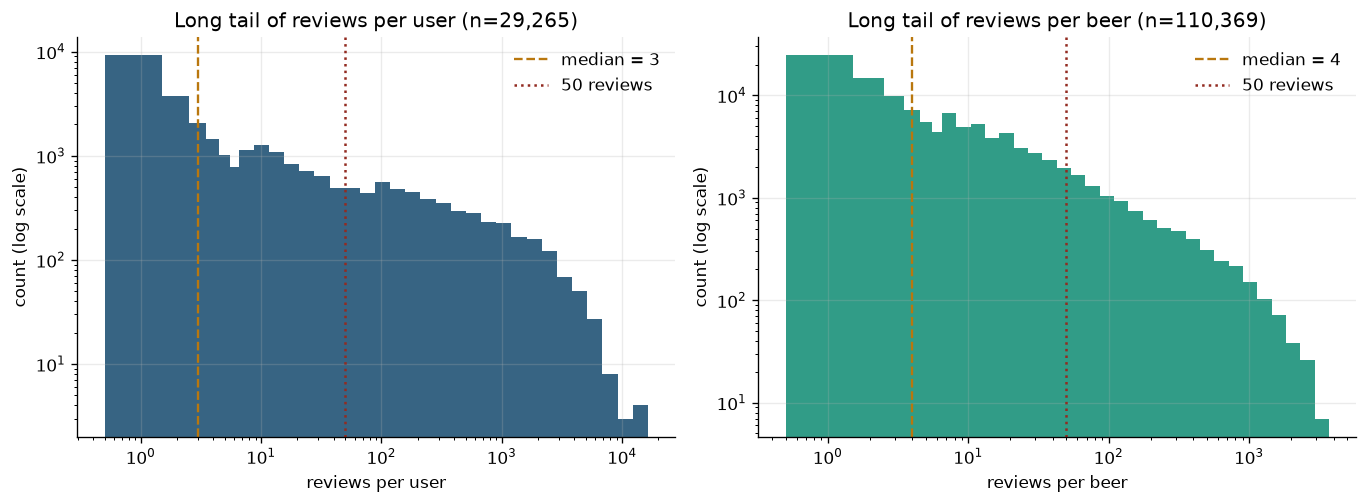

User–beer interaction matrix density: 0.09053% (2,924,163 reviews across 29,265 x 110,369 pairs)
Duplicate (user, beer) pairs: 68,931 pairs have >1 review (68,931 extra reviews, 2.36% of rows; max 2 for one pair).
Of those 68,931 repeated pairs, 68,931 share an identical timestamp and 68,930 share an identical overall rating (2,855,232 unique user–beer interactions remain after deduplication).


,entity,unique,median,mean,p90,max,eq_1,eq_1_share,ge_2,ge_5,ge_50,review_share_ge_5,review_share_ge_50
0,user,29265,3.0,99.920144,149.0,16364,9215,0.314881,20050,12766,4798,0.990174,0.949436
1,beer,110369,4.0,26.494423,41.0,3696,24566,0.222581,85803,53875,9459,0.961475,0.737277


In [5]:
u_counts = reviews.groupby("user", observed=True).size()
b_counts = reviews.groupby("beer_id", observed=True).size()

n_users = len(u_counts)
n_beers = len(b_counts)
density = len(reviews) / (n_users * n_beers)

# Exact (user, beer) pair multiplicity in O(N).
u_codes = reviews["user"].cat.codes.to_numpy(dtype=np.int64)
b_codes = reviews["beer_id"].cat.codes.to_numpy(dtype=np.int64)
pair_keys = u_codes * n_beers + b_codes
_, pair_counts = np.unique(pair_keys, return_counts=True)
n_unique_pairs = len(pair_counts)
n_repeated_pairs = int((pair_counts > 1).sum())
n_extra_dup_rows = int((pair_counts - 1).sum())

# Check whether repeated (user, beer) rows are re-reviews or identical scrape duplicates.
dup_mask = reviews.duplicated(subset=["user", "beer_id"], keep=False)
dup_pairs = reviews.loc[dup_mask, ["user", "beer_id", "review_time", "overall"]]
same_time_dups = int(
    (dup_pairs.groupby(["user", "beer_id"], observed=True)["review_time"].nunique() == 1).sum()
)
same_score_dups = int(
    (dup_pairs.groupby(["user", "beer_id"], observed=True)["overall"].nunique() == 1).sum()
)

def activity_row(name: str, counts: pd.Series) -> dict:
    total_reviews = int(counts.sum())
    return {
        "entity": name,
        "unique": len(counts),
        "median": float(counts.median()),
        "mean": float(counts.mean()),
        "p90": float(counts.quantile(0.90)),
        "max": int(counts.max()),
        "eq_1": int((counts == 1).sum()),
        "eq_1_share": float((counts == 1).mean()),
        "ge_2": int((counts >= 2).sum()),
        "ge_5": int((counts >= 5).sum()),
        "ge_50": int((counts >= 50).sum()),
        "review_share_ge_5": float(counts[counts >= 5].sum() / total_reviews),
        "review_share_ge_50": float(counts[counts >= 50].sum() / total_reviews),
    }

activity_table = pd.DataFrame([
    activity_row("user", u_counts),
    activity_row("beer", b_counts),
])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for ax, counts, label, color in [
    (axes[0], u_counts, "reviews per user", COLORS["primary"]),
    (axes[1], b_counts, "reviews per beer", COLORS["teal"]),
]:
    bins = np.concatenate([
        np.arange(0.5, 6.5, 1.0),
        np.logspace(np.log10(6.5), np.log10(counts.max() + 1), 28),
    ])
    ax.hist(counts.values, bins=bins, color=color, alpha=0.88)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axvline(counts.median(), color=COLORS["amber"], linestyle="--", linewidth=1.4, label=f"median = {counts.median():.0f}")
    ax.axvline(50, color=COLORS["crimson"], linestyle=":", linewidth=1.5, label="50 reviews")
    ax.set_xlabel(label)
    ax.set_ylabel("count (log scale)")
    ax.set_title(f"Long tail of {label} (n={len(counts):,})")
    ax.legend(frameon=False)

fig.tight_layout()
plt.show()

print(f"User–beer interaction matrix density: {density:.5%} ({len(reviews):,} reviews across {n_users:,} x {n_beers:,} pairs)")
print(
    f"Duplicate (user, beer) pairs: {n_repeated_pairs:,} pairs have >1 review "
    f"({n_extra_dup_rows:,} extra reviews, {n_extra_dup_rows / len(reviews):.2%} of rows; max {int(pair_counts.max())} for one pair)."
)
print(
    f"Of those {n_repeated_pairs:,} repeated pairs, {same_time_dups:,} share an identical timestamp and "
    f"{same_score_dups:,} share an identical overall rating ({n_unique_pairs:,} unique user–beer interactions remain after deduplication)."
)
activity_table

### 2b. Variance explained by simple pre-review baselines

Before building collaborative filtering or feature-based regressors, we quantify how much variance in `review/overall` is captured by single-variable group averages: the global mean, style mean, brewer mean, user mean, and beer mean. Because singleton users and beers have zero in-sample residual by construction, we report the same variance decomposition both on all reviews and on the dense core where each group has at least 5 reviews.

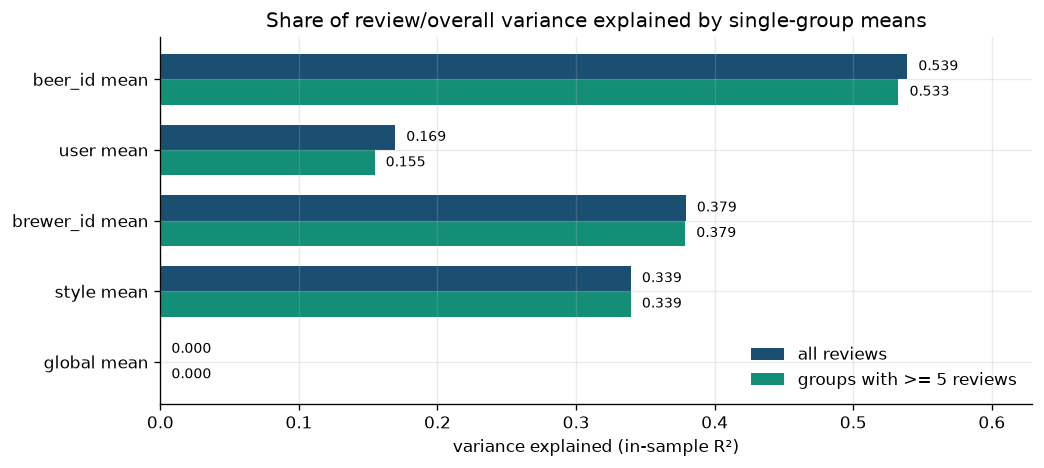

,baseline,groups,rmse_all,mae_all,r2_all,residual_var_share,core_coverage,r2_ge5_reviews,rmse_ge5_reviews
0,global mean,1,3.352579,2.546278,0.000000,1.000000,1.000000,0.000000,3.352579
1,style mean,89,2.724695,2.037094,0.339492,0.660508,1.000000,0.339492,2.724695
2,brewer_id mean,7547,2.641673,1.974051,0.379131,0.620869,0.999013,0.378749,2.642387
3,user mean,29265,3.055312,2.266176,0.169474,0.830526,0.990174,0.154630,3.057111
4,beer_id mean,110369,2.276382,1.642991,0.538967,0.461033,0.961475,0.532621,2.302813


In [6]:
y_all = reviews["overall"].to_numpy(dtype=np.float64)
global_mean = float(y_all.mean())
sst_all = float(np.sum((y_all - global_mean) ** 2))

def group_mean_metrics(group_col: str | None) -> dict:
    if group_col is None:
        pred = np.full_like(y_all, global_mean)
        n_groups = 1
        core_mask = np.ones(len(y_all), dtype=bool)
    else:
        g = reviews.groupby(group_col, observed=True)["overall"]
        means = g.transform("mean").to_numpy(dtype=np.float64)
        cnts = g.transform("count").to_numpy(dtype=np.int64)
        pred = means
        n_groups = int(reviews[group_col].nunique())
        core_mask = cnts >= 5

    resid = y_all - pred
    sse = float(np.sum(resid ** 2))
    r2 = 1.0 - sse / sst_all
    rmse = float(np.sqrt(sse / len(y_all)))
    mae = float(np.mean(np.abs(resid)))

    y_core = y_all[core_mask]
    p_core = pred[core_mask]
    sst_core = float(np.sum((y_core - y_core.mean()) ** 2))
    sse_core = float(np.sum((y_core - p_core) ** 2))
    r2_core = 1.0 - sse_core / sst_core
    rmse_core = float(np.sqrt(sse_core / len(y_core)))

    return {
        "baseline": "global mean" if group_col is None else f"{group_col} mean",
        "groups": n_groups,
        "rmse_all": rmse,
        "mae_all": mae,
        "r2_all": r2,
        "residual_var_share": 1.0 - r2,
        "core_coverage": float(core_mask.mean()),
        "r2_ge5_reviews": r2_core,
        "rmse_ge5_reviews": rmse_core,
    }

baseline_table = pd.DataFrame([
    group_mean_metrics(None),
    group_mean_metrics("style"),
    group_mean_metrics("brewer_id"),
    group_mean_metrics("user"),
    group_mean_metrics("beer_id"),
])

fig, ax = plt.subplots(figsize=(8.8, 4.0))
y_pos = np.arange(len(baseline_table))
h = 0.36
ax.barh(y_pos + h / 2, baseline_table["r2_all"], height=h, color=COLORS["primary"], label="all reviews")
ax.barh(y_pos - h / 2, baseline_table["r2_ge5_reviews"], height=h, color=COLORS["teal"], label="groups with >= 5 reviews")
for i, (r_all, r_core) in enumerate(zip(baseline_table["r2_all"], baseline_table["r2_ge5_reviews"])):
    ax.text(r_all + 0.008, i + h / 2, f"{r_all:.3f}", va="center", fontsize=8.5)
    ax.text(r_core + 0.008, i - h / 2, f"{r_core:.3f}", va="center", fontsize=8.5)
ax.set_yticks(y_pos, baseline_table["baseline"])
ax.set_xlim(0, max(baseline_table["r2_all"].max() + 0.09, 0.55))
ax.set_xlabel("variance explained (in-sample R²)")
ax.set_title("Share of review/overall variance explained by single-group means")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

baseline_table

### 2c. Beer attributes: ABV and style

When a beer has few past ratings, content metadata such as alcohol by volume (`beer/ABV`) and style (`beer/style`) can inform predictions. Below we check the ABV distribution, mean `review/overall` across ABV bins (including missing ABV as its own bucket), and mean ratings for the 15 most frequently reviewed styles.

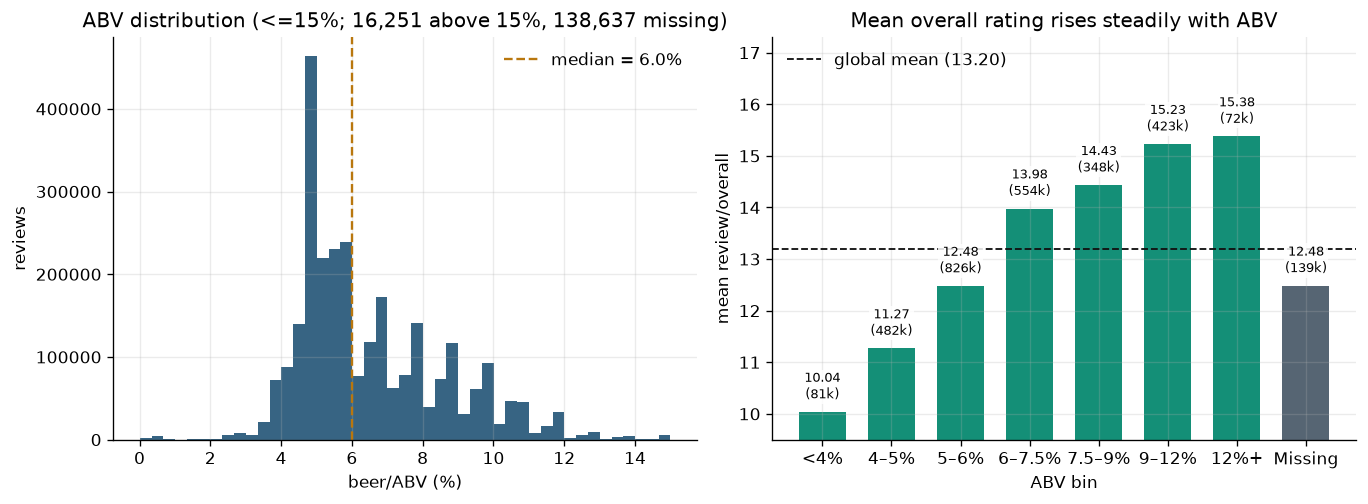

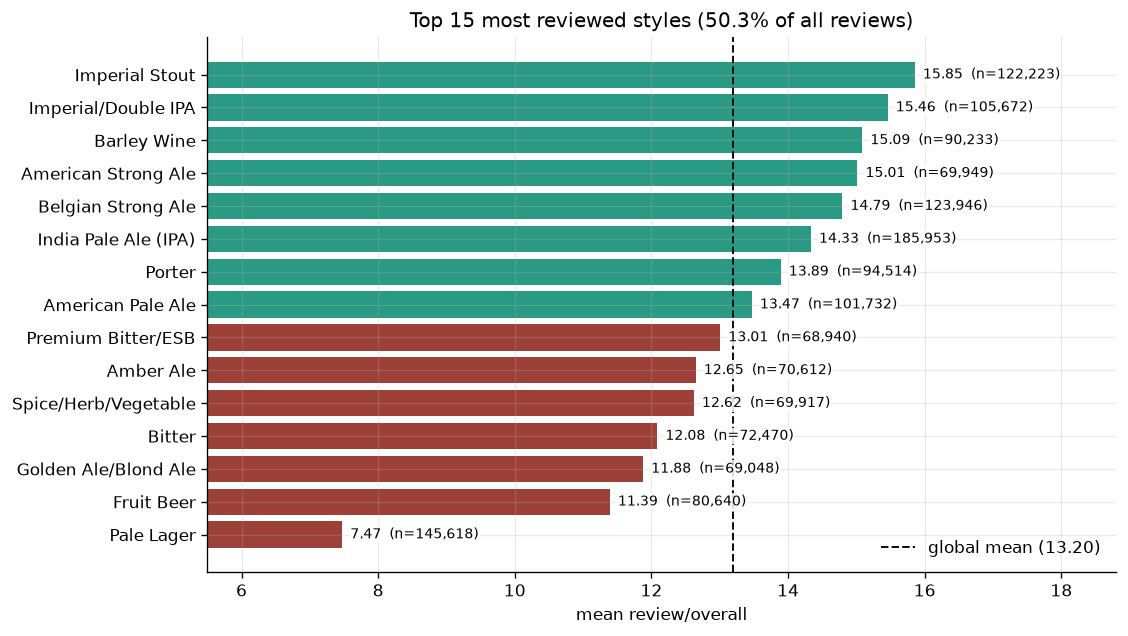

,style,reviews,mean_overall,std_overall,mean_abv,share
0,India Pale Ale (IPA),185953,14.333106,2.355078,6.565320,0.063592
1,Pale Lager,145618,7.472916,4.035080,4.688780,0.049798
2,Belgian Strong Ale,123946,14.793128,2.321681,9.198605,0.042387
3,Imperial Stout,122223,15.854144,2.201826,10.194411,0.041798
4,Imperial/Double IPA,105672,15.457047,2.090615,9.109757,0.036138
5,American Pale Ale,101732,13.467375,2.522550,5.439184,0.034790
6,Porter,94514,13.890291,2.525721,5.640641,0.032322
7,Barley Wine,90233,15.085024,2.437597,10.949435,0.030858
8,Fruit Beer,80640,11.389410,3.819551,5.536319,0.027577
9,Bitter,72470,12.084421,2.517338,4.160666,0.024783


In [7]:
abv_valid = reviews["abv"].dropna()
abv_cap = 15.0
n_above_cap = int((abv_valid > abv_cap).sum())

abv_bins = [-np.inf, 4.0, 5.0, 6.0, 7.5, 9.0, 12.0, np.inf]
abv_labels = ["<4%", "4–5%", "5–6%", "6–7.5%", "7.5–9%", "9–12%", "12%+"]
abv_cat = pd.cut(reviews["abv"], bins=abv_bins, labels=abv_labels, right=False)
abv_cat = abv_cat.cat.add_categories(["Missing"]).fillna("Missing")

abv_summary = (
    reviews.assign(abv_bin=abv_cat)
    .groupby("abv_bin", observed=True)["overall"]
    .agg(reviews="count", mean_overall="mean", std_overall="std")
    .reset_index()
)
abv_summary["share"] = abv_summary["reviews"] / len(reviews)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
axes[0].hist(abv_valid[abv_valid <= abv_cap], bins=45, color=COLORS["primary"], alpha=0.88)
axes[0].axvline(float(abv_valid.median()), color=COLORS["amber"], linestyle="--", linewidth=1.4, label=f"median = {abv_valid.median():.1f}%")
axes[0].set_xlabel("beer/ABV (%)")
axes[0].set_ylabel("reviews")
axes[0].set_title(f"ABV distribution (<=15%; {n_above_cap:,} above 15%, {reviews['abv'].isna().sum():,} missing)")
axes[0].legend(frameon=False)

x = np.arange(len(abv_summary))
bin_colors = [COLORS["slate"] if lbl == "Missing" else COLORS["teal"] for lbl in abv_summary["abv_bin"]]
axes[1].bar(x, abv_summary["mean_overall"], color=bin_colors, width=0.68)
axes[1].axhline(global_mean, color="#111111", linestyle="--", linewidth=1.1, label=f"global mean ({global_mean:.2f})")
for i, (m, cnt) in enumerate(zip(abv_summary["mean_overall"], abv_summary["reviews"])):
    axes[1].text(
        i, m + 0.18, f"{m:.2f}\n({cnt/1e3:.0f}k)", ha="center", va="bottom", fontsize=7.5,
        bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85),
    )
axes[1].set_xticks(x, abv_summary["abv_bin"])
axes[1].set_ylim(9.5, 17.3)
axes[1].set_xlabel("ABV bin")
axes[1].set_ylabel("mean review/overall")
axes[1].set_title("Mean overall rating rises steadily with ABV")
axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

style_stats = (
    reviews.groupby("style", observed=True)
    .agg(
        reviews=("overall", "count"),
        mean_overall=("overall", "mean"),
        std_overall=("overall", "std"),
        mean_abv=("abv", "mean"),
    )
    .reset_index()
)
style_stats["share"] = style_stats["reviews"] / len(reviews)
top15_styles = style_stats.nlargest(15, "reviews").sort_values("mean_overall", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.5, 5.4))
bar_cols = [COLORS["teal"] if v >= global_mean else COLORS["crimson"] for v in top15_styles["mean_overall"]]
ax.barh(top15_styles["style"], top15_styles["mean_overall"], color=bar_cols, alpha=0.9)
ax.axvline(global_mean, color="#111111", linestyle="--", linewidth=1.2, label=f"global mean ({global_mean:.2f})")
for i, (m, cnt) in enumerate(zip(top15_styles["mean_overall"], top15_styles["reviews"])):
    ax.text(
        m + 0.12, i, f"{m:.2f}  (n={cnt:,})", va="center", fontsize=8.5,
        bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85),
    )
ax.set_xlim(5.5, 18.8)
ax.set_xlabel("mean review/overall")
ax.set_title(f"Top 15 most reviewed styles ({top15_styles['share'].sum():.1%} of all reviews)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

top15_styles.sort_values("reviews", ascending=False).reset_index(drop=True)

### 2d. Time trend, temporal split feasibility, and user experience

Timestamps allow a realistic chronological train/test split where past reviews predict future ratings. Ordering reviews by time within each user also exposes the expertise effect documented by McAuley and Leskovec (WWW 2013): average ratings shift as users accumulate more reviews. To separate within-user evolution from selection effects (heavy reviewers differing from casual ones), we plot both all users and the cohort of users who eventually reach at least 200 reviews.

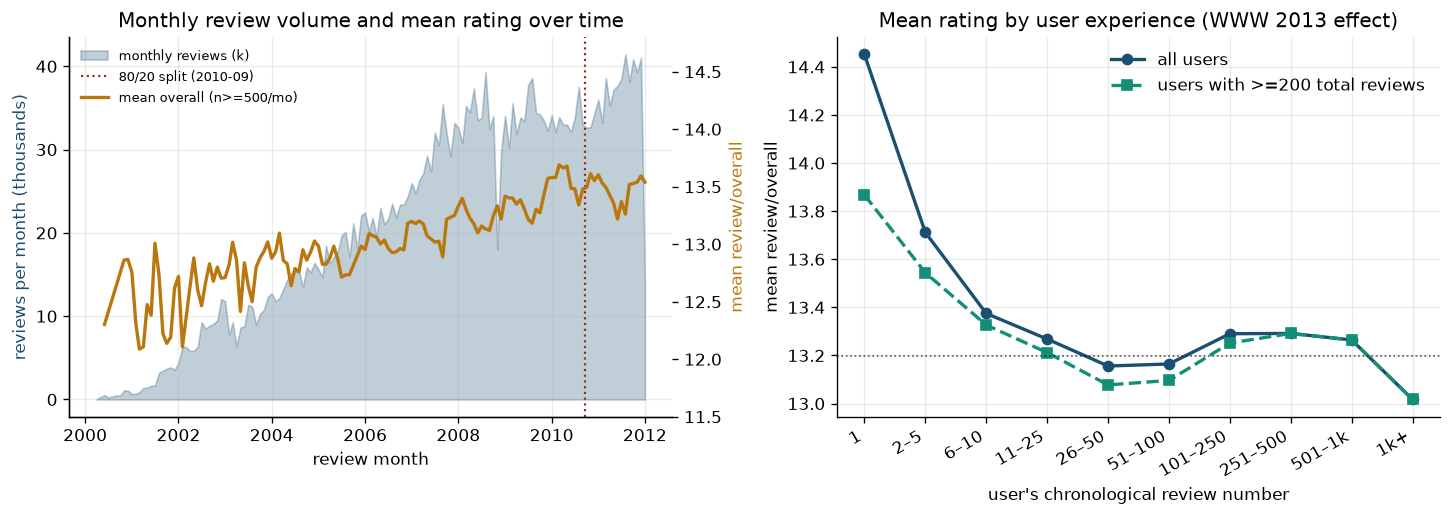

Chronological 80/20 split falls on 2010-09-17.
In the last 20% of reviews: 81.8% are by previously seen users, 75.3% are for previously seen beers, and 59.6% have both user and beer seen.


,exp_bin,reviews,mean_overall,reviews_vet,mean_overall_vet
0,1,29265,14.451563,2467,13.867451
1,2–5,63297,13.711597,9868,13.544082
2,6–10,52208,13.374808,12335,13.326713
3,11–25,109174,13.268352,37005,13.211998
4,26–50,133812,13.156212,61675,13.077568
5,51–100,208089,13.164618,123350,13.096133
6,101–250,411176,13.290416,362086,13.251647
7,251–500,422251,13.291646,422251,13.291646
8,501–1k,502427,13.264524,502427,13.264524
9,1k+,992464,13.017062,992464,13.017062


In [8]:
months = reviews["review_time"].dt.tz_localize(None).dt.to_period("M")
monthly = (
    reviews.assign(month=months)
    .groupby("month", observed=True)["overall"]
    .agg(reviews="count", mean_overall="mean")
    .reset_index()
)
monthly["month_dt"] = monthly["month"].dt.to_timestamp()

# Chronological 80/20 split diagnostics.
time_order = np.argsort(reviews["review_time"].to_numpy(), kind="mergesort")
split_pos = int(len(reviews) * 0.80)
train_idx = time_order[:split_pos]
test_idx = time_order[split_pos:]
split_date = reviews["review_time"].iloc[test_idx[0]]

train_users = set(reviews["user"].iloc[train_idx].unique())
train_beers = set(reviews["beer_id"].iloc[train_idx].unique())
test_user_seen = float(reviews["user"].iloc[test_idx].isin(train_users).mean())
test_beer_seen = float(reviews["beer_id"].iloc[test_idx].isin(train_beers).mean())
test_both_seen = float(
    (reviews["user"].iloc[test_idx].isin(train_users) & reviews["beer_id"].iloc[test_idx].isin(train_beers)).mean()
)

# User experience curve (chronological nth review per user).
ordered = reviews.iloc[time_order][["user", "overall"]]
user_nth = ordered.groupby("user", observed=True).cumcount() + 1
user_total = ordered.groupby("user", observed=True)["overall"].transform("count")

exp_bins = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, np.inf]
exp_labels = ["1", "2–5", "6–10", "11–25", "26–50", "51–100", "101–250", "251–500", "501–1k", "1k+"]
exp_cat = pd.cut(user_nth, bins=exp_bins, labels=exp_labels)

exp_all = (
    ordered.assign(exp_bin=exp_cat)
    .groupby("exp_bin", observed=True)["overall"]
    .agg(reviews="count", mean_overall="mean")
    .reset_index()
)
exp_vet = (
    ordered.loc[user_total >= 200]
    .assign(exp_bin=exp_cat[user_total >= 200])
    .groupby("exp_bin", observed=True)["overall"]
    .agg(reviews_vet="count", mean_overall_vet="mean")
    .reset_index()
)
exp_table = exp_all.merge(exp_vet, on="exp_bin", how="left")

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))

ax1 = axes[0]
ax1.fill_between(monthly["month_dt"], monthly["reviews"] / 1e3, color=COLORS["primary"], alpha=0.28, label="monthly reviews (k)")
ax1.set_ylabel("reviews per month (thousands)", color=COLORS["primary"])
ax1.set_xlabel("review month")
ax1.axvline(split_date.tz_localize(None), color=COLORS["crimson"], linestyle=":", linewidth=1.3, label=f"80/20 split ({split_date.strftime('%Y-%m')})")

ax1b = ax1.twinx()
stable_months = monthly.loc[monthly["reviews"] >= 500]
ax1b.plot(stable_months["month_dt"], stable_months["mean_overall"], color=COLORS["amber"], linewidth=2.0, label="mean overall (n>=500/mo)")
ax1b.set_ylabel("mean review/overall", color=COLORS["amber"])
ax1b.set_ylim(11.5, 14.8)
ax1b.spines["top"].set_visible(False)
ax1b.grid(False)
ax1.set_title("Monthly review volume and mean rating over time")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1b.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False, fontsize=8)

ax2 = axes[1]
x_exp = np.arange(len(exp_table))
ax2.plot(x_exp, exp_table["mean_overall"], marker="o", linewidth=2.0, color=COLORS["primary"], label="all users")
ax2.plot(x_exp, exp_table["mean_overall_vet"], marker="s", linewidth=2.0, linestyle="--", color=COLORS["teal"], label="users with >=200 total reviews")
ax2.axhline(global_mean, color="#111111", linestyle=":", linewidth=1.0, alpha=0.7)
ax2.set_xticks(x_exp, exp_table["exp_bin"], rotation=30, ha="right")
ax2.set_xlabel("user's chronological review number")
ax2.set_ylabel("mean review/overall")
ax2.set_title("Mean rating by user experience (WWW 2013 effect)")
ax2.legend(frameon=False, loc="upper right")

fig.tight_layout()
plt.show()

print(f"Chronological 80/20 split falls on {split_date.strftime('%Y-%m-%d')}.")
print(
    f"In the last 20% of reviews: {test_user_seen:.1%} are by previously seen users, "
    f"{test_beer_seen:.1%} are for previously seen beers, and {test_both_seen:.1%} have both user and beer seen."
)
exp_table

## 3. Aspect scores from the same review (same-review leakage check)

Each RateBeer submission records four aspect sub-scores (`appearance`, `aroma`, `palate`, `taste`) alongside `review/overall`. Because those four numbers are entered by the same user at the exact moment they assign `review/overall`, they are unavailable before a review is written. Using them as predictors of `review/overall` constitutes label leakage for pre-review recommendation. Below we measure their correlations and linear in-sample \(R^2\) strictly as a same-review ceiling.

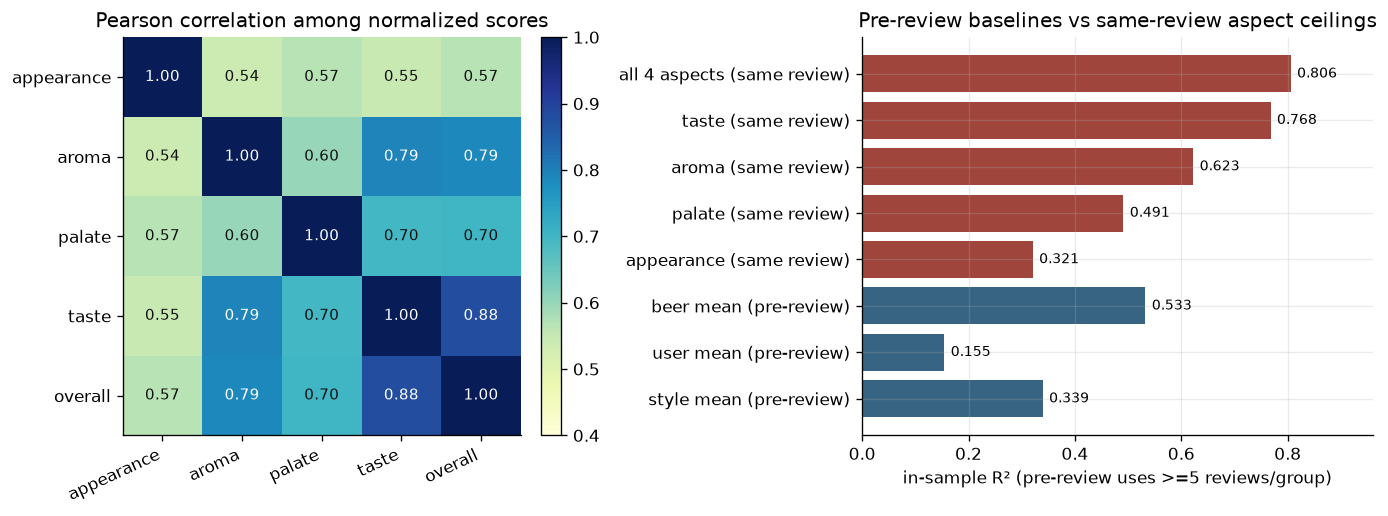

OLS ceiling equation (same-review leakage): overall ≈ 0.08 + 0.23*appearance + 0.45*aroma + 0.55*palate + 1.19*taste


,same_review_input (leakage ceiling),pearson_r_with_overall,in_sample_r2,in_sample_rmse
0,appearance,0.566359,0.320763,2.763056
1,aroma,0.789023,0.622557,2.059702
2,palate,0.700894,0.491253,2.391278
3,taste,0.876243,0.767802,1.615504
4,all 4 aspects (OLS ceiling),0.897586,0.805661,1.477948


In [9]:
norm_cols = ["appearance_norm", "aroma_norm", "palate_norm", "taste_norm", "overall_norm"]
short_labels = ["appearance", "aroma", "palate", "taste", "overall"]
corr_mat = reviews[norm_cols].astype(np.float64).corr()
corr_mat.index = short_labels
corr_mat.columns = short_labels

aspect_names = ["appearance", "aroma", "palate", "taste"]
X_aspects = reviews[aspect_names].to_numpy(dtype=np.float64)
y_ov = reviews["overall"].to_numpy(dtype=np.float64)
sst = float(np.sum((y_ov - y_ov.mean()) ** 2))

ceiling_rows = []
for i, name in enumerate(aspect_names):
    r = float(corr_mat.loc[name, "overall"])
    r2 = r ** 2
    rmse = float(np.sqrt((1.0 - r2) * sst / len(y_ov)))
    ceiling_rows.append({
        "same_review_input (leakage ceiling)": name,
        "pearson_r_with_overall": r,
        "in_sample_r2": r2,
        "in_sample_rmse": rmse,
    })

# Joint OLS ceiling across all four same-review aspects.
X_design = np.column_stack([np.ones(len(y_ov)), X_aspects])
beta, *_ = np.linalg.lstsq(X_design, y_ov, rcond=None)
pred_all4 = X_design @ beta
sse_all4 = float(np.sum((y_ov - pred_all4) ** 2))
r2_all4 = 1.0 - sse_all4 / sst
rmse_all4 = float(np.sqrt(sse_all4 / len(y_ov)))
ceiling_rows.append({
    "same_review_input (leakage ceiling)": "all 4 aspects (OLS ceiling)",
    "pearson_r_with_overall": float(np.sqrt(r2_all4)),
    "in_sample_r2": r2_all4,
    "in_sample_rmse": rmse_all4,
})
aspect_ceiling_table = pd.DataFrame(ceiling_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.4))

im = axes[0].imshow(corr_mat.values, vmin=0.4, vmax=1.0, cmap="YlGnBu")
axes[0].set_xticks(range(len(short_labels)), short_labels, rotation=25, ha="right")
axes[0].set_yticks(range(len(short_labels)), short_labels)
axes[0].grid(False)
for i in range(len(short_labels)):
    for j in range(len(short_labels)):
        val = corr_mat.values[i, j]
        txt_color = "white" if val > 0.75 else "#111111"
        axes[0].text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_color, fontsize=9)
axes[0].set_title("Pearson correlation among normalized scores")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

compare_labels = [
    "style mean (pre-review)",
    "user mean (pre-review)",
    "beer mean (pre-review)",
    "appearance (same review)",
    "palate (same review)",
    "aroma (same review)",
    "taste (same review)",
    "all 4 aspects (same review)",
]
b_lookup = baseline_table.set_index("baseline")["r2_ge5_reviews"]
c_lookup = aspect_ceiling_table.set_index("same_review_input (leakage ceiling)")["in_sample_r2"]
compare_vals = [
    b_lookup["style mean"],
    b_lookup["user mean"],
    b_lookup["beer_id mean"],
    c_lookup["appearance"],
    c_lookup["palate"],
    c_lookup["aroma"],
    c_lookup["taste"],
    c_lookup["all 4 aspects (OLS ceiling)"],
]
compare_colors = [COLORS["primary"]] * 3 + [COLORS["crimson"]] * 5
y_c = np.arange(len(compare_labels))
axes[1].barh(y_c, compare_vals, color=compare_colors, alpha=0.88)
for i, v in enumerate(compare_vals):
    axes[1].text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=8.5)
axes[1].set_yticks(y_c, compare_labels)
axes[1].set_xlim(0, 0.96)
axes[1].set_xlabel("in-sample R² (pre-review uses >=5 reviews/group)")
axes[1].set_title("Pre-review baselines vs same-review aspect ceilings")

fig.tight_layout()
plt.show()

print(
    "OLS ceiling equation (same-review leakage): "
    f"overall ≈ {beta[0]:.2f} + {beta[1]:.2f}*appearance + {beta[2]:.2f}*aroma "
    f"+ {beta[3]:.2f}*palate + {beta[4]:.2f}*taste"
)
aspect_ceiling_table

## 4. Review text: coverage, length, and sentiment vocabulary

Nearly every review includes free text. To test whether text carries rating signal beyond length without holding a 2.9-million-document matrix in memory, we inspect the word-count distribution, mean `review/overall` across length brackets, and smoothed token log-odds comparing high-rated (`overall >= 17`) against low-rated (`overall <= 10`) reviews from the streaming pass.

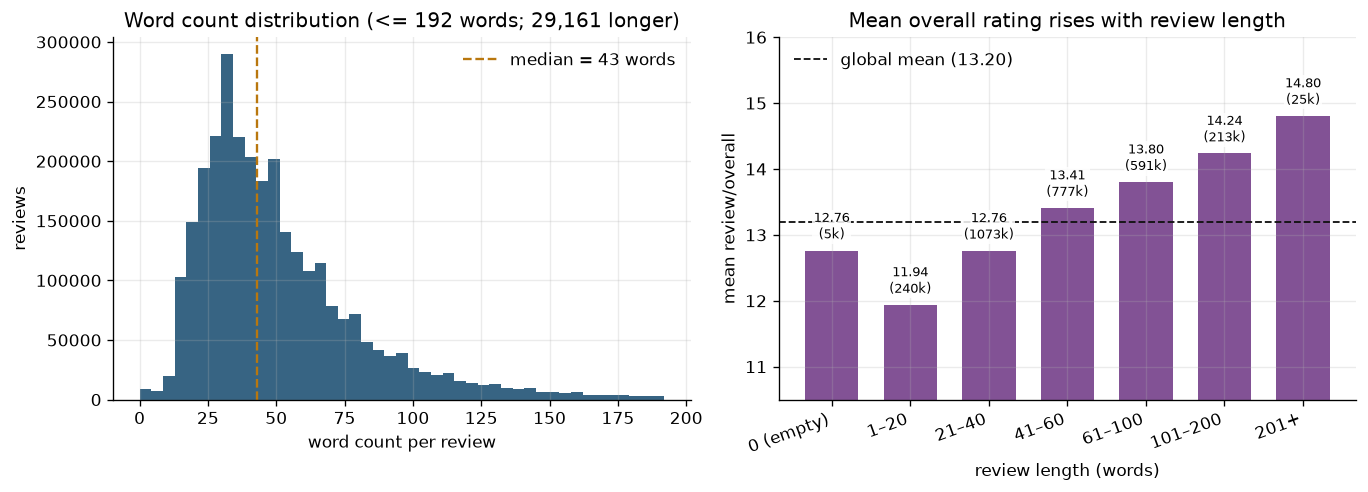

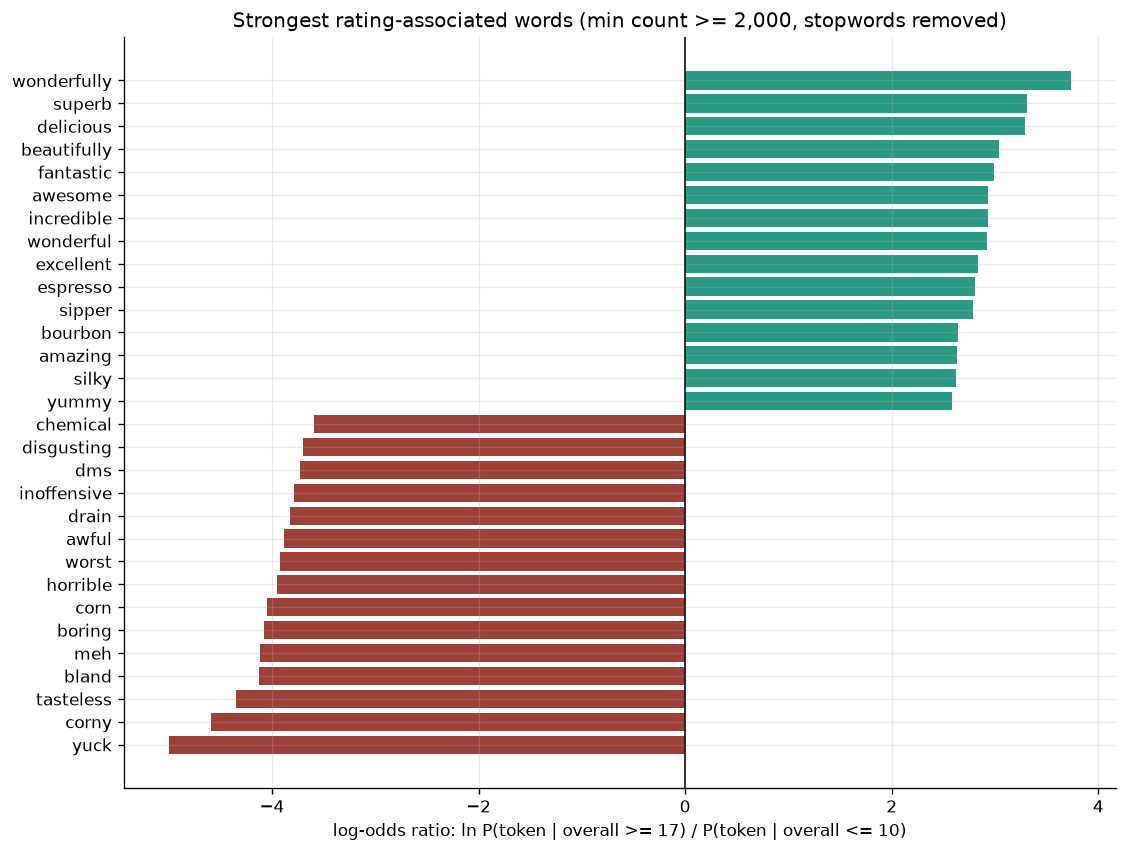

Reviews with text: 99.83% (5,002 empty). Word count: median 43, mean 52.9, 95th pct 119. Pearson r(word_count, overall) = 0.162.
Streaming token pass: 381,698 high-rated docs (>=17) vs 515,057 low-rated docs (<=10); 1,528 tokens met the >= 2,000 threshold.


,length_bin,reviews,mean_overall,std_overall,share
0,0 (empty),5002,12.762295,4.440555,0.001711
1,1–20,239912,11.937252,4.024404,0.082045
2,21–40,1072606,12.759030,3.327408,0.366808
3,41–60,776886,13.407619,3.126736,0.265678
4,61–100,591302,13.799989,3.121574,0.202212
5,101–200,213258,14.235077,3.237678,0.072930
6,201+,25197,14.804421,3.351813,0.008617


,token,high_count,low_count,total_count,log_odds_high_vs_low
0,wonderfully,4090,90,4180,3.734347
1,superb,3543,119,3662,3.314182
2,delicious,19121,665,19786,3.285967
3,beautifully,2655,118,2773,3.034115
4,fantastic,13332,626,13958,2.985713
5,awesome,14775,731,15506,2.933641
6,incredible,5527,273,5800,2.933115
7,wonderful,20678,1039,21717,2.918560
8,yuck,14,2070,2084,-4.999074
9,corny,60,5591,5651,-4.589556


In [10]:
wc = reviews["word_count"].to_numpy(dtype=np.float64)
has_text_rate = float(reviews["has_text"].mean())
empty_text_n = int((~reviews["has_text"]).sum())
wc_cap = int(np.percentile(wc, 99))
wc_corr = float(np.corrcoef(wc, reviews["overall"].to_numpy(dtype=np.float64))[0, 1])

wc_bins = [-1, 0, 20, 40, 60, 100, 200, np.inf]
wc_labels = ["0 (empty)", "1–20", "21–40", "41–60", "61–100", "101–200", "201+"]
wc_cat = pd.cut(reviews["word_count"], bins=wc_bins, labels=wc_labels)
wc_summary = (
    reviews.assign(length_bin=wc_cat)
    .groupby("length_bin", observed=True)["overall"]
    .agg(reviews="count", mean_overall="mean", std_overall="std")
    .reset_index()
)
wc_summary["share"] = wc_summary["reviews"] / len(reviews)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].hist(wc[wc <= wc_cap], bins=45, color=COLORS["primary"], alpha=0.88)
axes[0].axvline(float(np.median(wc)), color=COLORS["amber"], linestyle="--", linewidth=1.4, label=f"median = {np.median(wc):.0f} words")
axes[0].set_xlabel("word count per review")
axes[0].set_ylabel("reviews")
axes[0].set_title(f"Word count distribution (<= {wc_cap} words; {(wc > wc_cap).sum():,} longer)")
axes[0].legend(frameon=False)

x_w = np.arange(len(wc_summary))
axes[1].bar(x_w, wc_summary["mean_overall"], color=COLORS["purple"], alpha=0.85, width=0.68)
axes[1].axhline(global_mean, color="#111111", linestyle="--", linewidth=1.1, label=f"global mean ({global_mean:.2f})")
for i, (m, cnt) in enumerate(zip(wc_summary["mean_overall"], wc_summary["reviews"])):
    axes[1].text(
        i, m + 0.12, f"{m:.2f}\n({cnt/1e3:.0f}k)", ha="center", va="bottom", fontsize=7.5,
        bbox=dict(facecolor="white", edgecolor="none", pad=0.8, alpha=0.85),
    )
axes[1].set_xticks(x_w, wc_summary["length_bin"], rotation=20, ha="right")
axes[1].set_ylim(10.5, 16.0)
axes[1].set_xlabel("review length (words)")
axes[1].set_ylabel("mean review/overall")
axes[1].set_title("Mean overall rating rises with review length")
axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

# Smoothed log-odds ratio from streaming token counts (high: >=17 vs low: <=10).
MIN_TOKEN_COUNT = 2000
low_c = meta["low_tokens"]
high_c = meta["high_tokens"]
vocab = {tok for tok in (set(low_c) | set(high_c)) if low_c[tok] + high_c[tok] >= MIN_TOKEN_COUNT}
total_low = sum(low_c[tok] for tok in vocab)
total_high = sum(high_c[tok] for tok in vocab)
alpha = 1.0
V = len(vocab)

token_rows = []
for tok in vocab:
    ch = high_c[tok]
    cl = low_c[tok]
    p_high = (ch + alpha) / (total_high + alpha * V)
    p_low = (cl + alpha) / (total_low + alpha * V)
    token_rows.append({
        "token": tok,
        "high_count": ch,
        "low_count": cl,
        "total_count": ch + cl,
        "log_odds_high_vs_low": float(np.log(p_high / p_low)),
    })

tok_df = pd.DataFrame(token_rows)
top_high = tok_df.nlargest(15, "log_odds_high_vs_low")
top_low = tok_df.nsmallest(15, "log_odds_high_vs_low")
plot_toks = pd.concat([top_low, top_high]).sort_values("log_odds_high_vs_low", ascending=True)

fig, ax = plt.subplots(figsize=(9.5, 7.2))
tok_colors = [COLORS["teal"] if v > 0 else COLORS["crimson"] for v in plot_toks["log_odds_high_vs_low"]]
ax.barh(plot_toks["token"], plot_toks["log_odds_high_vs_low"], color=tok_colors, alpha=0.9)
ax.axvline(0.0, color="#111111", linewidth=1.0)
ax.set_xlabel("log-odds ratio: ln P(token | overall >= 17) / P(token | overall <= 10)")
ax.set_title(f"Strongest rating-associated words (min count >= {MIN_TOKEN_COUNT:,}, stopwords removed)")
fig.tight_layout()
plt.show()

print(
    f"Reviews with text: {has_text_rate:.2%} ({empty_text_n:,} empty). "
    f"Word count: median {np.median(wc):.0f}, mean {np.mean(wc):.1f}, 95th pct {np.percentile(wc, 95):.0f}. "
    f"Pearson r(word_count, overall) = {wc_corr:.3f}."
)
print(
    f"Streaming token pass: {meta['n_high_docs']:,} high-rated docs (>=17) vs "
    f"{meta['n_low_docs']:,} low-rated docs (<=10); {V:,} tokens met the >= {MIN_TOKEN_COUNT:,} threshold."
)
display(wc_summary)
pd.concat([top_high.head(8), top_low.head(8)]).reset_index(drop=True)

## What this implies for the model

All three candidate formulations show clear statistical signal in `ratebeer.json.gz`, while differing sharply in what information is available at prediction time.

- **Same-review aspect scores (excluded due to leakage).** The four sensory sub-scores are strongly correlated with `review/overall` (`taste` alone reaches \(r = 0.876\), \(R^2 = 0.768\); `aroma` reaches \(r = 0.789\), \(R^2 = 0.623\)), and a simple linear combination of all four achieves an in-sample ceiling of \(R^2 = 0.806\) (RMSE `1.48` vs `3.35` global standard deviation). Because a reviewer submits these four numbers on the same form as `review/overall`, using them as predictors leaks the label and is excluded from the modeling task.
- **Review text (post-review sentiment task).** Text is present on `99.83%` of reviews (median `43` words), length correlates modestly with score (\(r = 0.162\), rising from `11.94` for 1–20 words to `14.80` for 201+ words), and streaming log-odds separate praise (`wonderfully`, `superb`, `delicious`, `fantastic`) from criticism and adjunct off-flavors (`yuck`, `corny`, `tasteless`, `bland`, `corn`). This makes text regression a valid post-hoc sentiment task, though the text exists only after the user has tasted and reviewed the beer, so it cannot score an unreviewed beer.
- **Pre-review user–beer rating prediction (selected task).** The dataset supports personalized rating regression using only fields known before the review is written:
  - **Substantial remaining variance.** On groups with at least 5 reviews, style mean explains \(R^2 = 0.339\) (RMSE `2.72`), brewer mean explains \(0.379\) (RMSE `2.64`), user mean explains \(0.155\) (RMSE `3.06`), and beer mean explains \(0.533\) (RMSE `2.30`), leaving `46.7%` of variance unexplained by beer identity alone.
  - **Deep repeat history for collaborative filtering.** Although the matrix is sparse (`0.0905%` density across `29,265` users and `110,369` beers), `20,050` users have at least 2 reviews, `12,766` users have at least 5 reviews (`99.0%` of all rows), and `4,798` users have at least 50 reviews (`94.9%` of all rows). Likewise, `53,875` beers have at least 5 reviews (`96.1%` of rows).
  - **Strong content metadata for cold-start rows.** The 89 styles span an 8.4-point spread among the top 15 styles alone (`Imperial Stout` at `15.85` vs `Pale Lager` at `7.47`), and mean `review/overall` rises monotonically across ABV bins (`10.04` below 4% ABV up to `15.38` above 12% ABV, with missing ABV cleanly handled as a separate indicator for the `4.74%` of rows encoded as `'-'`).
  - **Clean temporal split and a necessary deduplication step.** Every review carries a valid UTC timestamp (`2000-04-12` to `2012-01-13`), placing a chronological 80/20 split on `2010-09-17`, where `81.8%` of test reviews come from seen users, `75.3%` target seen beers, and `59.6%` have both seen. Deduplicating `(user, beer_id)` before splitting removes `68,931` identical-timestamp scrape duplicates (`2.36%` of rows), leaving `2,855,232` unique user–beer interactions.

**Task to carry forward.** Deduplicate repeated `(user, beer_id)` records, then predict `review/overall` (1–20 scale) on a chronological train/validation/test split using RMSE and MAE as primary metrics (reporting warm-pair and cold-start slices separately). Build from course baselines in order: (1) global mean, (2) regularized user + beer bias model, (3) item/user similarity or latent-factor matrix factorization, and (4) hybrid content extensions incorporating `beer/style`, `beer/ABV` (with a missingness indicator), and `beer/brewerId`. In error analysis and discussion, examine temporal drift and the WWW 2013 user-experience effect — ratings drop from `13.87` on a future veteran's first review to `13.08` by reviews 26–50 — as structured sources of residual error.